In [135]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [136]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [137]:
df=pd.read_csv('titanic_toy.csv')

In [138]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [139]:
df.shape

(891, 4)

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [141]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [142]:
# train test split
X=df.drop(columns=['Survived'])
y=df['Survived']

In [143]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [144]:
X_train.shape,X_test.shape

((712, 3), (179, 3))

In [145]:
X_train.isnull().mean()

Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64

In [146]:
mean_age=X_train['Age'].mean()
median_age = X_train['Age'].median()

mean_fare = X_train['Fare'].mean()
median_fare = X_train['Fare'].median()

In [147]:
X_train['Age_mean']=X_train['Age'].fillna(mean_age)
X_train['Age_median']=X_train['Age'].fillna(median_age)

X_train['Fare_mean']=X_train['Age'].fillna(mean_fare)
X_train['Fare_median']=X_train['Age'].fillna(median_fare)

In [148]:
X_train.sample(5)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
460,48.0,26.5500,0,48.000000,48.00,48.000000,48.0000
885,39.0,29.1250,5,39.000000,39.00,39.000000,39.0000
26,NaN,7.2250,0,29.785904,28.75,32.617597,14.4583
821,27.0,8.6625,0,27.000000,27.00,27.000000,27.0000
159,NaN,69.5500,10,29.785904,28.75,32.617597,14.4583


In [149]:
print('Original Age variable variance: ', X_train['Age'].var())
print('Age Variance after median imputation: ', X_train['Age_median'].var())
print('Age Variance after mean imputation: ', X_train['Age_mean'].var())

print('Original Fare variable variance: ', X_train['Fare'].var())
print('Fare Variance after median imputation: ', X_train['Fare_median'].var())
print('Fare Variance after mean imputation: ', X_train['Fare_mean'].var())

Original Age variable variance:  204.3495133904614
Age Variance after median imputation:  161.9895663346054
Age Variance after mean imputation:  161.81262452718673
Original Fare variable variance:  2448.197913706318
Fare Variance after median imputation:  200.55085535155024
Fare Variance after mean imputation:  163.1347828052615


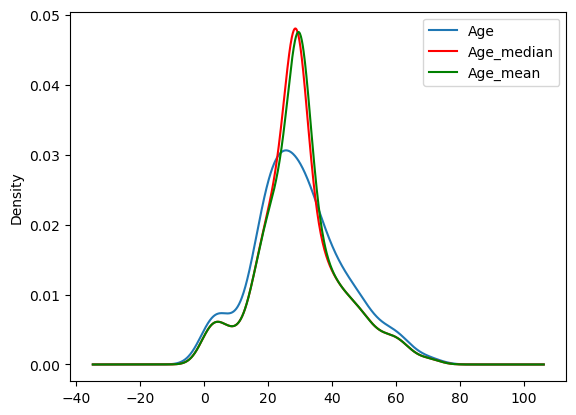

In [150]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
X_train['Age'].plot(kind='kde', ax=ax)

# variable imputed with the median
X_train['Age_median'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
X_train['Age_mean'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

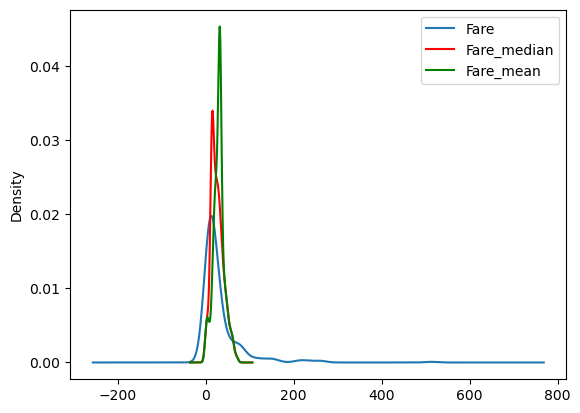

In [151]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
X_train['Fare'].plot(kind='kde', ax=ax)

# variable imputed with the median
X_train['Fare_median'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
X_train['Fare_mean'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [152]:
X_train.cov()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,204.349513,204.349513
Fare,70.719262,2448.197914,17.258917,55.603719,57.957599,49.169279,90.432552
Family,-6.498901,17.258917,2.735252,-5.146106,-5.112563,-5.237797,-4.649792
Age_mean,204.349513,55.603719,-5.146106,161.812625,161.812625,161.812625,161.812625
Age_median,204.349513,57.957599,-5.112563,161.812625,161.989566,161.328946,164.430718
Fare_mean,204.349513,49.169279,-5.237797,161.812625,161.328946,163.134783,154.655944
Fare_median,204.349513,90.432552,-4.649792,161.812625,164.430718,154.655944,200.550855


In [153]:
X_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.092644,-0.299113,1.000000,1.000000,1.000000,1.000000
Fare,0.092644,1.000000,0.208268,0.088069,0.091757,0.077538,0.128809
Family,-0.299113,0.208268,1.000000,-0.244610,-0.242883,-0.247957,-0.198528
Age_mean,1.000000,0.088069,-0.244610,1.000000,0.999454,0.995939,0.898243
Age_median,1.000000,0.091757,-0.242883,0.999454,1.000000,0.992420,0.912278
Fare_mean,1.000000,0.077538,-0.247957,0.995939,0.992420,1.000000,0.855029
Fare_median,1.000000,0.128809,-0.198528,0.898243,0.912278,0.855029,1.000000


<Axes: >

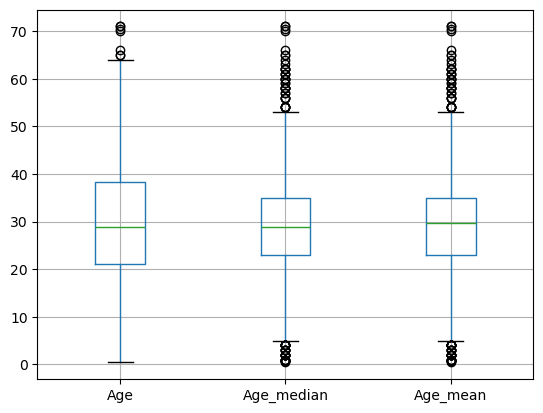

In [154]:
X_train[['Age', 'Age_median', 'Age_mean']].boxplot()

<Axes: >

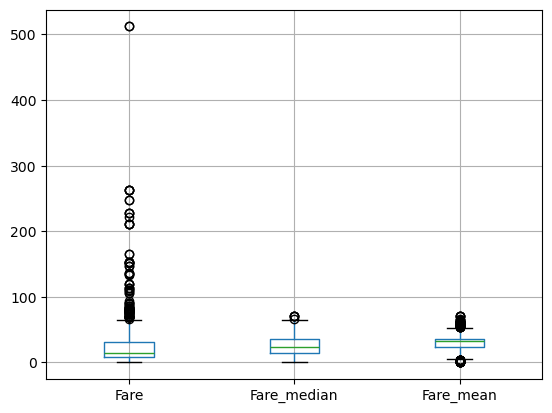

In [155]:
X_train[['Fare', 'Fare_median', 'Fare_mean']].boxplot()

# Using skLearn

In [156]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [157]:
imp1 = SimpleImputer(strategy = 'median')
imp2 = SimpleImputer(strategy = 'mean')

In [158]:
trf = ColumnTransformer([
    ('median_imp',imp1,['Age']),
    ('mean_imp',imp2,['Fare'])
], remainder='passthrough',force_int_remainder_cols=False)

In [159]:
trf.fit(X_train)

ColumnTransformer(force_int_remainder_cols=False, remainder='passthrough',
                  transformers=[('median_imp', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('mean_imp', SimpleImputer(), ['Fare'])])

In [160]:
X_train_trf=trf.transform(X_train)
X_test_trf = trf.transform(X_test)

In [166]:
X_train.head(50)

,Age,Fare,Family
30,40.0,27.7208,0
10,4.0,16.7000,2
873,47.0,9.0000,0
182,9.0,31.3875,6
876,20.0,9.8458,0
213,30.0,13.0000,0
157,30.0,8.0500,0
780,13.0,7.2292,0
572,36.0,26.3875,0
77,NaN,8.0500,0


In [163]:
X_train_trf=pd.DataFrame(X_train_trf,columns=X_train.columns)

In [167]:
X_train_trf.head(50)

,Age,Fare,Family
0,40.00,27.720800,0.0
1,4.00,16.700000,2.0
2,47.00,9.000000,0.0
3,9.00,31.387500,6.0
4,20.00,9.845800,0.0
5,30.00,13.000000,0.0
6,30.00,8.050000,0.0
7,13.00,7.229200,0.0
8,36.00,26.387500,0.0
9,28.75,8.050000,0.0


In [168]:
X_train.mean()

Age       29.785904
Fare      32.617597
Family     0.932584
dtype: float64

In [169]:
X_train_trf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 712 entries, 0 to 711
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     712 non-null    float64
 1   Fare    712 non-null    float64
 2   Family  712 non-null    float64
dtypes: float64(3)
memory usage: 16.8 KB
